**HW1
Chelsea Ankenbrandt**

**Question 1**

**a.**

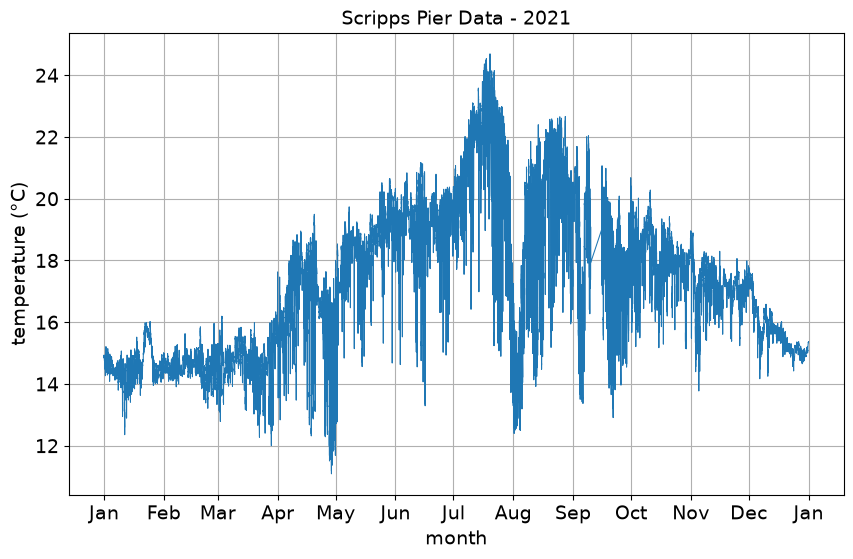

In [3]:
import os
from dataclasses import dataclass, field

import numpy as np
from netCDF4 import Dataset
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

#to import the data, I changed get_2020_pier_data to work for any year, xyear, passed as params
import get_xyear_pier_data 

#create a PierData object of 2021 data
temperature_2021 = get_xyear_pier_data.get_pier_data(xyear = 2021)

#plot the data
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(temperature_2021.dnum, temperature_2021.temperature, linewidth=.75)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.tick_params(labelsize=14)
ax.set_xlabel('month', fontsize=14)
ax.set_ylabel('temperature (°C)', fontsize=14)
ax.set_title('Scripps Pier Data - 2021', fontsize=14)
ax.grid(True)
plt.show()

This plot shows large temperature differences between the summer months and hte winter months. You can also see the general variability of the temperature is greatest in July and August, with a short period of unexpectedly (at least to me) cold water in the beginning of August. There is also a short gap in the data in September.

**b.**

In [4]:
print('The mean is:', np.mean(temperature_2021.temperature))
print('The standard deviation is:', np.std(temperature_2021.temperature, ddof=1))

The mean is: 17.273985
The standard deviation is: 2.4253728


This tells me the average temperature in 2021 was 17.3C. This is actually quite surprising, as I would've thought it was greater than that, but the consistent cold of the winter months pull it down quite a bit. 

The standard deviate shows that 68% of readings fell within 2.4 degrees of 17.3C. That ~5 degree window actually feels pretty small given the overall highs and lows of ~25C and ~11C, respectively.



**c.**

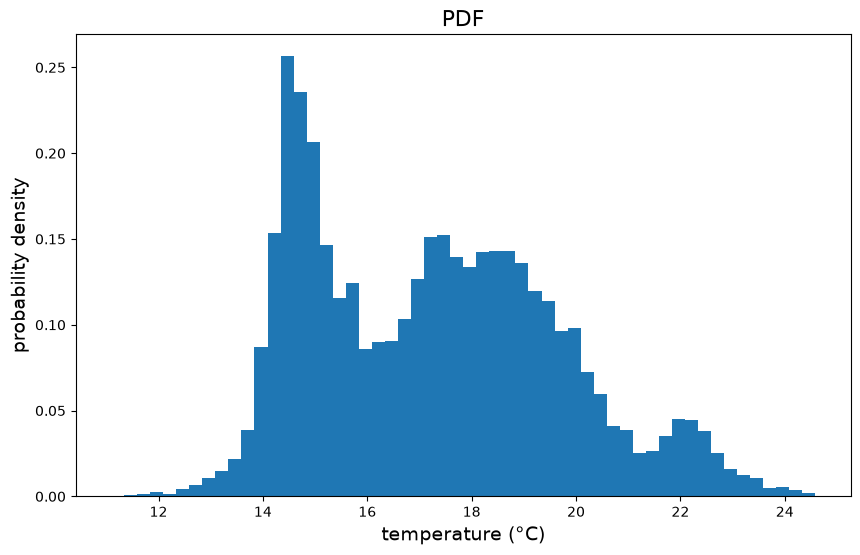

In [5]:
#set the bin size
pdfbins = np.arange(temperature_2021.temperature.min(), temperature_2021.temperature.max(), 0.25)

#make the plot
fig, ax1 = plt.subplots(figsize=(10, 6))
pdf = ax1.hist(temperature_2021.temperature, bins=pdfbins, density=True) # type: ignore
ax1.set_ylabel('probability density', fontsize=14)
ax1.set_xlabel('temperature (°C)', fontsize=14)
ax1.set_title('PDF', fontsize=16)
plt.show()

This plot is somewhat reminiscient of a bimodal distribution, with a cluster around 15C and another around 19C, however it doesn't fit cleanly! 

**Question 2**

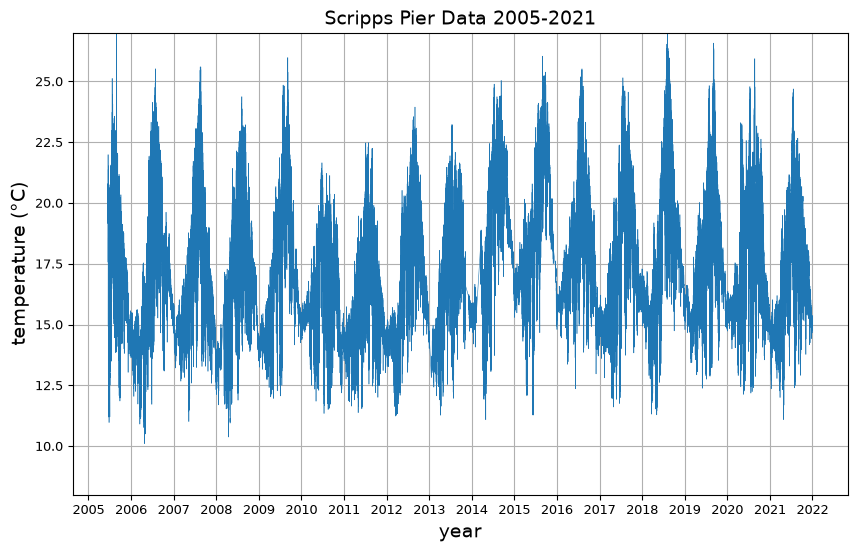

In [1]:
import os
from dataclasses import dataclass, field

import numpy as np
from netCDF4 import Dataset
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

#to import the data, I changed get_2020_pier_data to work for any year, xyear, passed as params
import get_xyear_pier_data 

#first, lets make a PierData object with the data of 2005-2021
pier_record = get_xyear_pier_data.get_pier_data(xyear = 2005)
for i in range(2006, 2022): 
    pier_record.temperature = np.concatenate([pier_record.temperature, get_xyear_pier_data.get_pier_data(xyear = i).temperature])
    pier_record.dnum = np.concatenate([pier_record.dnum, get_xyear_pier_data.get_pier_data(xyear = i).dnum])
    pier_record.pressure = np.concatenate([pier_record.pressure, get_xyear_pier_data.get_pier_data(xyear = i).pressure])

    #self-critique - I should've probably edited my get_pier_data function to do all the looping and concatenating
    #when given a specific date range, but this also works! 

#now we plot! 
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(pier_record.dnum, pier_record.temperature, linewidth=.4)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.tick_params(labelsize=9)
ax.set_ylim(top=27, bottom = 8)
ax.set_xlabel('year', fontsize=14)
ax.set_ylabel('temperature (°C)', fontsize=14)
ax.set_title('Scripps Pier Data 2005-2021', fontsize=14)
ax.grid(True)
plt.show()

You may see in this graph that I limited the max temperature to xx. This completely cuts out the extremely high value in 2005, which is an outlier and most likely a sampling error. 

In macro trends, I notice 2010 through 2013 had lower maximums in the summer than other years before and after. Higher minimum temperatures in the second half of 2014 and 2015 compared to other years are also visible, maybe relating to the strong el nino that was around that time. 

Now, let's look at the mean and standard deviation.

In [2]:
print('The mean is:', np.mean(pier_record.temperature))
print('The standard deviation is:', np.std(pier_record.temperature, ddof=1))

The mean is: 17.799152
The standard deviation is: 2.73943


The mean for the whole timeseries is actually slightly higher than 2021's mean, so 2021 was about half of a degree colder than the average of this 16 year span.

The standard deviation of the timeseries is marginally greater than the standard deviation of 2021. This is to be expected, as there is likely more temperature variance over a 16 year period than over a one year period. In fact, I am surprised by how similar the standard deviations are given the various climate cycles (especially the massive el nino event of 2014-2016) happening in this time period. 

Overall, I would say 2021 is not an exceptional year. It's results larely line up with the timeseries as a whole and it in fact shows less extremes than many other years in the series. 

Let's plot the summer of 2016 to look at any abnormalities there: 

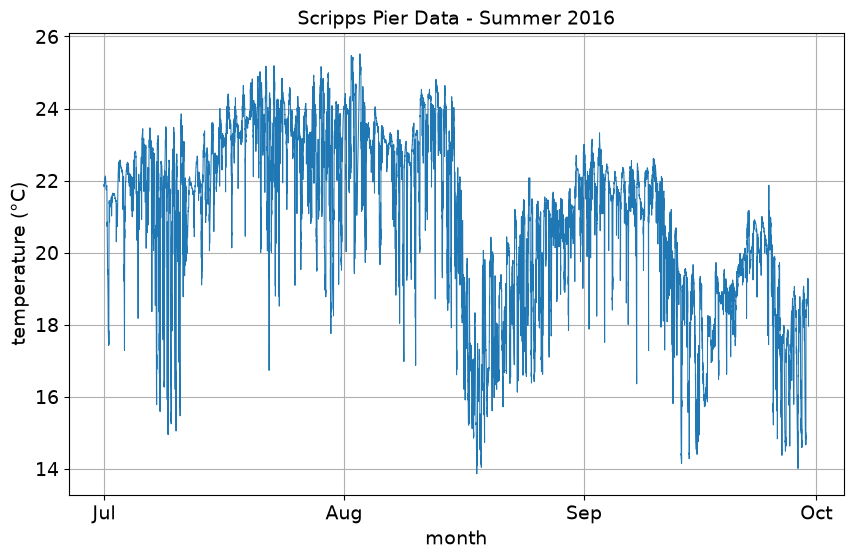

In [9]:
import os
from dataclasses import dataclass, field

import numpy as np
from netCDF4 import Dataset
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

#to import the data, I changed get_2020_pier_data to work for any year, xyear, passed as params
import get_xyear_pier_data 

#create a PierData object of 2016 data
temperature_2016 = get_xyear_pier_data.get_pier_data(xyear = 2016, date_start = '2016-07-01', date_end = '2016-09-30')

#plot the data
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(temperature_2016.dnum, temperature_2016.temperature, linewidth=.75)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.tick_params(labelsize=14)
ax.set_xlabel('month', fontsize=14)
ax.set_ylabel('temperature (°C)', fontsize=14)
ax.set_title('Scripps Pier Data - Summer 2016', fontsize=14)
ax.grid(True)
plt.show()

This shows a sharp drop in temperature in August 2016, likely from an upwelling event. Generally, I know these events are not uncommon here in San Diego (why some surfers complain about wearing board shorts one day and a wetsuit the next). In fact, if you look back at the 2021 data, there is also a summer upwelling event around the beginning of August that sharply pulls down the temperature for that time period. 

If you're curious about my changes to get_2021_pier_data and the helper get_xyear_pier_data.get_pier_data function that I use above, I put this entire assignment into a forked repo! https://github.com/cankenbrandt/SIO221a_Ankenbrandt